# Context-dependent FlexiTokens segmentation in FLORES

## Six-language deterministic analysis

This report asks a word-level question while keeping the **complete FLORES sentence** as FlexiTokens' model input: when the same written word occurs in different sentence contexts, how many distinct boundary patterns does it receive?

The analysis covers English (`en`), Spanish (`es`), Russian (`ru`), Ukrainian (`uk`), Hindi (`hi`), and Telugu (`te`) across FLORES `dev` and `devtest` (2,009 sentences per language).

## Method

- Each original sentence is passed to the trained FlexiTokens checkpoint once. No words are tokenized in isolation.
- Boundary decisions are deterministic: `sigmoid(boundary_logit) > 0.5`. Gumbel sampling is disabled; no seeds or sampling are used.
- GPT-2's ByteLevel pre-tokenizer locates candidate spans. Adjacent Unicode letters, marks, and numbers are joined into one word-like span so that Indic words are not broken at combining marks. Punctuation-only spans are excluded from the word plots.
- Word groups use lowercase forms (for example, `During` and `during` are grouped), while the model still sees the original sentence. The original surface form is retained in the occurrence tables.
- A tokenization is identified by the exact internal FlexiTokens boundary positions within the word. Different cut locations count as different tokenizations even if they produce the same number of pieces.

The evaluator and the complete occurrence-level outputs are in `flexitokens/src/eval/contextual_word_tokenization.py` and `results/contextual_word_tokenization_full_v1/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

plt.style.use('seaborn-v0_8-whitegrid')
LANGUAGES = ['en', 'es', 'ru', 'uk', 'hi', 'te']
LANGUAGE_NAMES = {'en': 'English', 'es': 'Spanish', 'ru': 'Russian', 'uk': 'Ukrainian', 'hi': 'Hindi', 'te': 'Telugu'}
candidate_roots = [Path('results/contextual_word_tokenization_full_v1'), Path('flexitokens/results/contextual_word_tokenization_full_v1')]
RESULTS_ROOT = next((path for path in candidate_roots if path.exists()), None)
if RESULTS_ROOT is None:
    raise FileNotFoundError('Could not locate results/contextual_word_tokenization_full_v1')

summaries = []
for language in LANGUAGES:
    with (RESULTS_ROOT / language / 'summary.json').open(encoding='utf-8') as handle:
        summaries.append(json.load(handle))
summary = pd.DataFrame(summaries).set_index('language').loc[LANGUAGES].reset_index()
summary['language_name'] = summary['language'].map(LANGUAGE_NAMES)
summary['intra_character_boundary_percent'] = 100 * summary['intra_character_boundary_occurrences'] / summary['word_occurrences']
print(f'Loaded six completed language checkpoints from: {RESULTS_ROOT.resolve()}')

Loaded six completed language checkpoints from: /Users/samarth.gaggar/Downloads/OSU Tokenization/flexitokens/results/contextual_word_tokenization_full_v1


## Corpus coverage and primary outcome

A **repeated word** appears at least twice in one language. Only repeated words can demonstrate contextual variation. The percentage below is therefore: repeated lowercase word groups with more than one observed boundary pattern, divided by all repeated lowercase word groups.

In [2]:
coverage = summary[[
    'language_name', 'sentences', 'word_occurrences', 'unique_lowercase_words',
    'repeated_words', 'repeated_words_with_variation',
    'percent_repeated_words_with_variation'
]].rename(columns={
    'language_name': 'Language', 'sentences': 'Sentences', 'word_occurrences': 'Word occurrences',
    'unique_lowercase_words': 'Lowercase word groups', 'repeated_words': 'Repeated word groups',
    'repeated_words_with_variation': 'Repeated groups with >1 pattern',
    'percent_repeated_words_with_variation': 'Variation rate (%)'
})
display(coverage.style.format({'Variation rate (%)': '{:.2f}'}))

total_repeated = int(summary['repeated_words'].sum())
total_variable = int(summary['repeated_words_with_variation'].sum())
overall_rate = 100 * total_variable / total_repeated
display(Markdown(
    f'Across the six separate language vocabularies, **{total_variable:,} of {total_repeated:,} repeated word groups ({overall_rate:.2f}%)** received more than one observed FlexiTokens boundary pattern.'
))

,Language,Sentences,Word occurrences,Lowercase word groups,Repeated word groups,Repeated groups with >1 pattern,Variation rate (%)
0,English,2009,43612,8393,3939,846,21.48
1,Spanish,2009,51014,10326,4291,636,14.82
2,Russian,2009,39119,14453,4480,954,21.29
3,Ukrainian,2009,38044,14144,4412,957,21.69
4,Hindi,2009,50608,8592,3761,831,22.10
5,Telugu,2009,34102,12998,4165,977,23.46


Across the six separate language vocabularies, **5,201 of 25,048 repeated word groups (20.76%)** received more than one observed FlexiTokens boundary pattern.

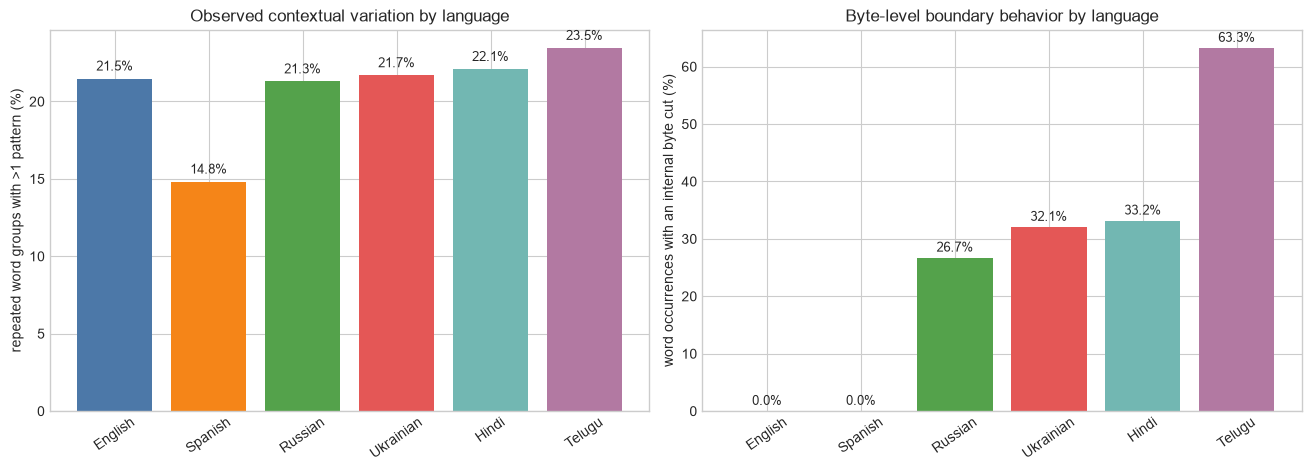

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
colors = ['#4C78A8', '#F58518', '#54A24B', '#E45756', '#72B7B2', '#B279A2']
axes[0].bar(summary['language_name'], summary['percent_repeated_words_with_variation'], color=colors)
axes[0].set_ylabel('repeated word groups with >1 pattern (%)')
axes[0].set_title('Observed contextual variation by language')
axes[0].tick_params(axis='x', rotation=35)
for bar, value in zip(axes[0].patches, summary['percent_repeated_words_with_variation']):
    axes[0].text(bar.get_x() + bar.get_width()/2, value + 0.35, f'{value:.1f}%', ha='center', va='bottom', fontsize=9)

axes[1].bar(summary['language_name'], summary['intra_character_boundary_percent'], color=colors)
axes[1].set_ylabel('word occurrences with an internal byte cut (%)')
axes[1].set_title('Byte-level boundary behavior by language')
axes[1].tick_params(axis='x', rotation=35)
for bar, value in zip(axes[1].patches, summary['intra_character_boundary_percent']):
    axes[1].text(bar.get_x() + bar.get_width()/2, value + 0.6, f'{value:.1f}%', ha='center', va='bottom', fontsize=9)
plt.show()

The right panel is a representation note, not a quality score. FlexiTokens operates over byte-level inputs. For Cyrillic, Devanagari, and Telugu, a predicted boundary can fall inside the UTF-8 bytes of one visible character. Those cuts are retained exactly in the occurrence files as byte offsets; the report does not silently round them to a different character-level segmentation.

## How many patterns does a repeated word receive?

This plot separates words with one pattern from those with two, three, four, or at least five patterns. It avoids singleton word groups, which cannot reveal variation across contexts.

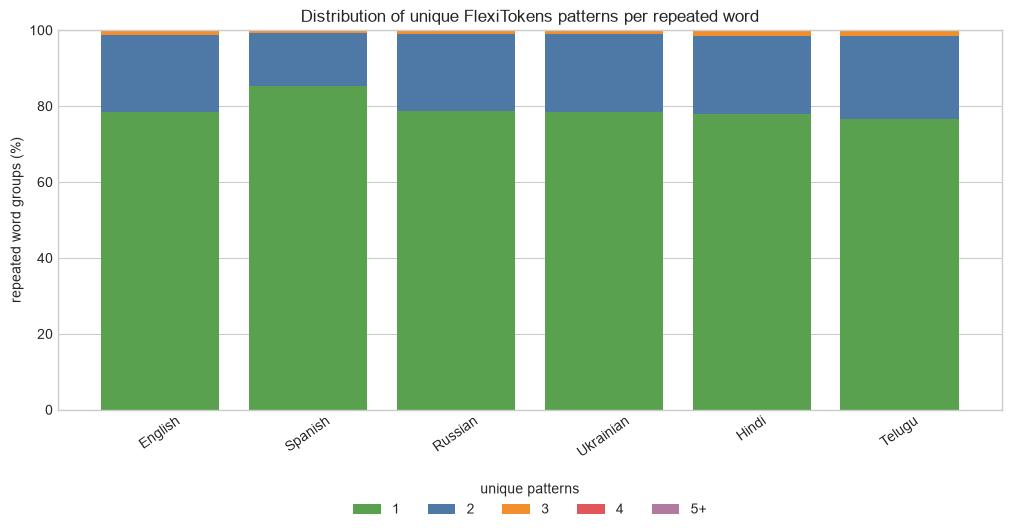

,1,2,3,4,5+
language,,,,,
en,3093,791,50,4,1
es,3655,603,32,1,0
ru,3526,908,43,3,0
uk,3455,916,39,2,0
hi,2930,772,57,2,0
te,3188,909,63,4,1


In [4]:
distribution_rows = []
for row in summary.itertuples():
    distribution = row.repeated_word_variant_distribution
    for pattern_count, count in distribution.items():
        bucket = int(pattern_count) if int(pattern_count) < 5 else 5
        distribution_rows.append({'language': row.language, 'bucket': bucket, 'count': int(count)})
distribution = pd.DataFrame(distribution_rows).pivot(index='language', columns='bucket', values='count').fillna(0).reindex(LANGUAGES)
distribution.columns = ['1', '2', '3', '4', '5+']

fig, axis = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
left = pd.Series(0, index=distribution.index, dtype=float)
stack_colors = ['#59A14F', '#4E79A7', '#F28E2B', '#E15759', '#B07AA1']
for color, bucket in zip(stack_colors, distribution.columns):
    values = 100 * distribution[bucket] / distribution.sum(axis=1)
    axis.bar([LANGUAGE_NAMES[x] for x in distribution.index], values, bottom=left, label=bucket, color=color)
    left += values
axis.set_ylabel('repeated word groups (%)')
axis.set_title('Distribution of unique FlexiTokens patterns per repeated word')
axis.tick_params(axis='x', rotation=35)
axis.legend(title='unique patterns', ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.16))
plt.show()
display(distribution.astype(int))

## Words selected for inspection

The table below is a ranking aid, not a claim that a word has a bad tokenization. It includes only words observed at least five times, then ranks by number of patterns, variation score, and occurrence count. A rare second pattern should be interpreted differently from several common patterns.

In [5]:
top_rows = []
for language in LANGUAGES:
    words = pd.read_csv(RESULTS_ROOT / language / 'word_summary.csv')
    selected = words[(words['occurrence_count'] >= 5) & (words['unique_tokenizations'] > 1)].sort_values(
        ['unique_tokenizations', 'variation_score', 'occurrence_count'], ascending=False
    ).head(5).copy()
    selected['language'] = LANGUAGE_NAMES[language]
    top_rows.append(selected)
top_words = pd.concat(top_rows, ignore_index=True)[[
    'language', 'lowercase_word', 'occurrence_count', 'unique_tokenizations',
    'dominant_segmentation_display', 'dominant_percentage', 'variation_score'
]]
top_words = top_words.rename(columns={
    'language': 'Language', 'lowercase_word': 'Word', 'occurrence_count': 'Occurrences',
    'unique_tokenizations': 'Unique patterns', 'dominant_segmentation_display': 'Most common pattern',
    'dominant_percentage': 'Most common (%)', 'variation_score': 'Variation score'
})
display(top_words.style.format({'Most common (%)': '{:.1f}', 'Variation score': '{:.3f}'}))

,Language,Word,Occurrences,Unique patterns,Most common pattern,Most common (%),Variation score
0,English,comfortable,6,5,comfort|able,33.3,0.667
1,English,virtual,7,4,V|ir|t|ual,42.9,0.571
2,English,reading,9,4,read|ing,44.4,0.556
3,English,learning,19,4,learning,63.2,0.368
4,English,during,52,4,during,63.5,0.365
5,Spanish,contemplar,6,4,conte|m|p|l|ar,33.3,0.667
6,Spanish,además,40,3,adem|ás,40.0,0.600
7,Spanish,únicamente,7,3,únicam|ente,42.9,0.571
8,Spanish,temperatura,7,3,temper|atura,42.9,0.571
9,Spanish,aproximadamente,13,3,aproximadam|ente,46.2,0.538


## Manual-inspection workflow

Each language directory contains `manual_inspection_template.csv`. It provides one representative sentence for every observed pattern among high-variation repeated words. The next research step is to read those contexts and label each difference cautiously as potentially meaningful, likely formatting-related, or unclear. The tables below are **candidates for review**, not automatic semantic conclusions.

In [6]:
review_rows = []
for language in LANGUAGES:
    review = pd.read_csv(RESULTS_ROOT / language / 'manual_inspection_template.csv')
    if not review.empty:
        review = review.head(3).copy()
        review['Language'] = LANGUAGE_NAMES[language]
        review['Sentence context'] = review['sentence'].str.slice(0, 180)
        review_rows.append(review[['Language', 'lowercase_word', 'segmentation_display', 'pattern_count', 'pattern_percentage', 'Sentence context']])
if review_rows:
    review_examples = pd.concat(review_rows, ignore_index=True).rename(columns={
        'lowercase_word': 'Word', 'segmentation_display': 'Observed pattern',
        'pattern_count': 'Pattern count', 'pattern_percentage': 'Pattern (%)'
    })
    display(review_examples.style.format({'Pattern (%)': '{:.1f}'}))
else:
    print('No repeated words with multiple patterns met the inspection threshold.')

,Language,Word,Observed pattern,Pattern count,Pattern (%),Sentence context
0,English,comfortable,comfort|able,2,33.3,Tournament top seeds South Africa started on the right note when they had a comfortable 26 - 00 win against 5th seeded Zambia.
1,English,comfortable,comfor|t|ab|le,1,16.7,"MetroPlus is more comfortable and less crowded but slightly more expensive, though still cheaper than normal metro tickets in Europe."
2,English,comfortable,comf|or|t|ab|le,1,16.7,"After you become comfortable with formatting and editing on the web, then later, you might create your own website."
3,Spanish,contemplar,conte|m|p|l|ar,2,33.3,"Una fantástica forma de contemplar todo el encanto de la región del sur África es ingresar en automóvil, lo que, a su vez, le permitirá acceder a lugares fuera de las rutas turísti"
4,Spanish,contemplar,conte|mp|l|ar,2,33.3,"La solución viene de la mano de la tecnología, a través de las excursiones virtuales. Los alumnos pueden observar los objetos exhibidos en un museo, visitar un acuario o contemplar"
5,Spanish,contemplar,conte|mp|lar,1,16.7,"A bordo de un bote es la mejor forma de contemplar los lugares y la vida silvestre de Galápagos, al igual que lo hizo Charles Darwin en 1835."
6,Russian,настолько,настол|ько,4,40.0,"Он продолжил и сказал: ""Этот случай серьёзный. Будьте уверены, что наша система работает настолько хорошо, насколько должна""."
7,Russian,настолько,"настолько [byte cuts: 7,12]",3,30.0,"Клетки настолько существенны и важны для изучения жизни, что фактически их обычно называют ""строительными кирпичиками жизни""."
8,Russian,настолько,настол|ьк|о,2,20.0,"Федерация гимнастики США и Олимпийский комитет США имеют одинаковую цель — сделать гимнастику и другие виды спорта настолько безопасными для спортсменов, насколько это возможно, чт"
9,Ukrainian,настільки,настільк|и,3,33.3,"Місце катастрофи було знайдене сьогодні, і воно є настільки недоступним, що двох поліцейських було скинуто у джунглі для того, щоб вони пройшли до цього місця пішки і пошукали тих,"


## Case-matched sensitivity check

The primary analysis follows the requested lowercase grouping. This supplementary check groups exact surface forms instead, so `During` and `during` are not treated as the same word. It uses the saved occurrence data and does not rerun FlexiTokens.

In [7]:
case_rows = []
for language in LANGUAGES:
    occurrences = pd.read_csv(RESULTS_ROOT / language / 'word_occurrences.csv')
    exact = occurrences.groupby('surface_word')['boundary_signature'].agg(['size', 'nunique'])
    repeated = exact[exact['size'] >= 2]
    variable = repeated[repeated['nunique'] > 1]
    case_rows.append({
        'Language': LANGUAGE_NAMES[language],
        'Repeated exact-surface forms': len(repeated),
        'Exact-surface forms with >1 pattern': len(variable),
        'Exact-surface variation rate (%)': 100 * len(variable) / len(repeated) if len(repeated) else 0,
    })
case_summary = pd.DataFrame(case_rows)
display(case_summary.style.format({'Exact-surface variation rate (%)': '{:.2f}'}))

comparison = coverage[['Language', 'Variation rate (%)']].merge(
    case_summary[['Language', 'Exact-surface variation rate (%)']], on='Language'
)
comparison['Difference from lowercase grouping (percentage points)'] = (
    comparison['Variation rate (%)'] - comparison['Exact-surface variation rate (%)']
)
display(comparison.style.format({
    'Variation rate (%)': '{:.2f}',
    'Exact-surface variation rate (%)': '{:.2f}',
    'Difference from lowercase grouping (percentage points)': '{:.2f}',
}))

,Language,Repeated exact-surface forms,Exact-surface forms with >1 pattern,Exact-surface variation rate (%)
0,English,4142,592,14.29
1,Spanish,4431,483,10.90
2,Russian,4511,563,12.48
3,Ukrainian,4434,554,12.49
4,Hindi,3759,831,22.11
5,Telugu,4164,977,23.46


,Language,Variation rate (%),Exact-surface variation rate (%),Difference from lowercase grouping (percentage points)
0,English,21.48,14.29,7.18
1,Spanish,14.82,10.90,3.92
2,Russian,21.29,12.48,8.81
3,Ukrainian,21.69,12.49,9.20
4,Hindi,22.10,22.11,-0.01
5,Telugu,23.46,23.46,-0.01


## Interpretation and limits

1. More observed patterns are not automatically bad. They may reflect genuine context or meaning differences, or they may reflect unstable boundaries. Pattern frequencies and sentence contexts must be inspected together.
2. Lowercase grouping may combine capitalization-driven differences with context-driven differences. The occurrence files preserve the original surface forms, allowing a case-matched supplementary analysis without rerunning the model.
3. Byte-internal boundaries are reported faithfully. For non-Latin scripts, an exact model-level segmentation may not always be displayable as separate valid Unicode characters; the byte-offset signature is the authoritative record.
4. This notebook reports measured segmentation behavior. It does not claim that a variation is semantically meaningful until the saved representative contexts have been manually reviewed.

## Reproducibility

The computation is implemented in `flexitokens/src/eval/contextual_word_tokenization.py`. Each completed language checkpoint includes: `sentence_boundaries.csv`, `word_occurrences.csv`, `word_summary.csv`, `tokenization_patterns.csv`, `manual_inspection_template.csv`, four language-level figures, and `summary.json`. `progress.json` records the completed languages.